# Projector calibration, simulated end to end

The lenses after the specimen map a ray at the specimen to the camera as
$x_d = A\,x_s + B\,\theta_s$. $A$ is the magnification and $B$ the camera length; both are complex,
carrying the image rotation. A beam **shift** moves the beam centroid by $A\cdot$shift and a
**tilt** by $B\cdot$tilt, whatever the beam looks like. The calibration fits a lens model that
predicts $A$ and $B$ for any **lens setting** at any HT.

A lens setting is the four free-lens **DAC values** (IL1, IL2, IL3, PL1). Each is a number from 0 to
65535 that sets a lens current.

| block | what is done | frames | result |
|---|---|---|---|
| stage 1 (60 kV, no specimen) | 9 lens settings, ± shift and ± tilt at each | 36 | lens setting + kick → beam position |
| anchors (cross grating with gold) | grating image, gold ring pattern | 2 | metres and radians |
| stage 2 (60 + 80 kV, no specimen) | replay at 80 kV, then 30 designed settings at both HTs | 276 | lens and camera positions |

The simulated microscope holds the hidden column and returns only camera frames. The experiment
code sees lens settings, HTs, deflector commands and frames, as on the real microscope; the truth
is used only to score.

**Simulation conventions:**
- infinite dose;
- a centroid floor of 0.01 px per frame (drift, lens return);
- paraxial optics, linear and pure deflectors;
- the 80 kV kick factor recalibrated.

The mathematics is in `projector_calibration_outline.md`.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # small fits; keeps the GPU free

import numpy as np
import projector_calibration as P
import projector_figures as F

F.apply_style()
scope = P.SimulatedMicroscope(v0=60e3, floor_px=0.01, kick_errors=(0.07, -0.06), camera_rotation=0.6, seed=5)
setup = P.Setup(v0=60e3, v1=80e3, base_dac=scope.base_dac(), set_d=scope.find_diffraction_set(ring_px=80))
TRUTH = scope.truth()        # for scoring only

F.table(["lens setting", "IL1", "IL2", "IL3", "PL1", "how it is chosen"],
        [[F.SET_LABELS[i], *[f"{v:,.0f}" for v in dac],
          "the 40k row, read from the console" if i == 0 else "found by eye: rings on the camera" if i == 8
          else "fixed multiple of the 40k row"] for i, dac in enumerate(setup.sets)])

| lens setting | IL1 | IL2 | IL3 | PL1 | how it is chosen |
|---|---|---|---|---|---|
| 0 | 21,534 | 12,814 | 18,319 | 32,985 | the 40k row, read from the console |
| 1 | 12,885 | 12,814 | 18,319 | 32,985 | fixed multiple of the 40k row |
| 2 | 21,534 | 12,814 | 12,885 | 32,985 | fixed multiple of the 40k row |
| 3 | 21,534 | 12,814 | 18,319 | 19,791 | fixed multiple of the 40k row |
| 4 | 21,534 | 12,814 | 18,554 | 16,493 | fixed multiple of the 40k row |
| 5 | 21,534 | 20,616 | 18,319 | 19,791 | fixed multiple of the 40k row |
| 6 | 21,534 | 20,616 | 18,554 | 32,985 | fixed multiple of the 40k row |
| 7 | 21,534 | 20,616 | 18,319 | 16,493 | fixed multiple of the 40k row |
| D | 21,534 | 21,527 | 14,042 | 32,985 | found by eye: rings on the camera |

## 1. The hidden column

Five hard-edge solenoid lenses (objective, IL1–IL3, PL1) and a drift to the camera. The model
has 16 parameters: 6 gaps, 5 lens lengths, the objective strength, and 4 lens gains (strength
per DAC unit). A lens's strength is gain × DAC value × p(60 kV)/p(V). The fit adds the camera
rotation and the two deflector scales.

The figure shows the column as in the paper: lenses as ellipses, the camera at its true width,
and a parallel 40 nm beam at the specimen (green) carried down the column. Where the band pinches
there is a crossover (a diffraction plane). The beam's size is printed at the specimen and at the
camera. The transverse axis is linear near the axis and logarithmic further out, so both are
visible.

- At **setting 0** (the 40k row) the beam reaches the camera magnified 40 000 times, in focus.
- At **setting D** the camera sits in a diffraction plane ($A = 0$): the parallel beam collapses to
  a point.
- At **80 kV** the same DAC values make every lens 14% weaker: the crossovers move and the
  magnification drops to about 11 000.

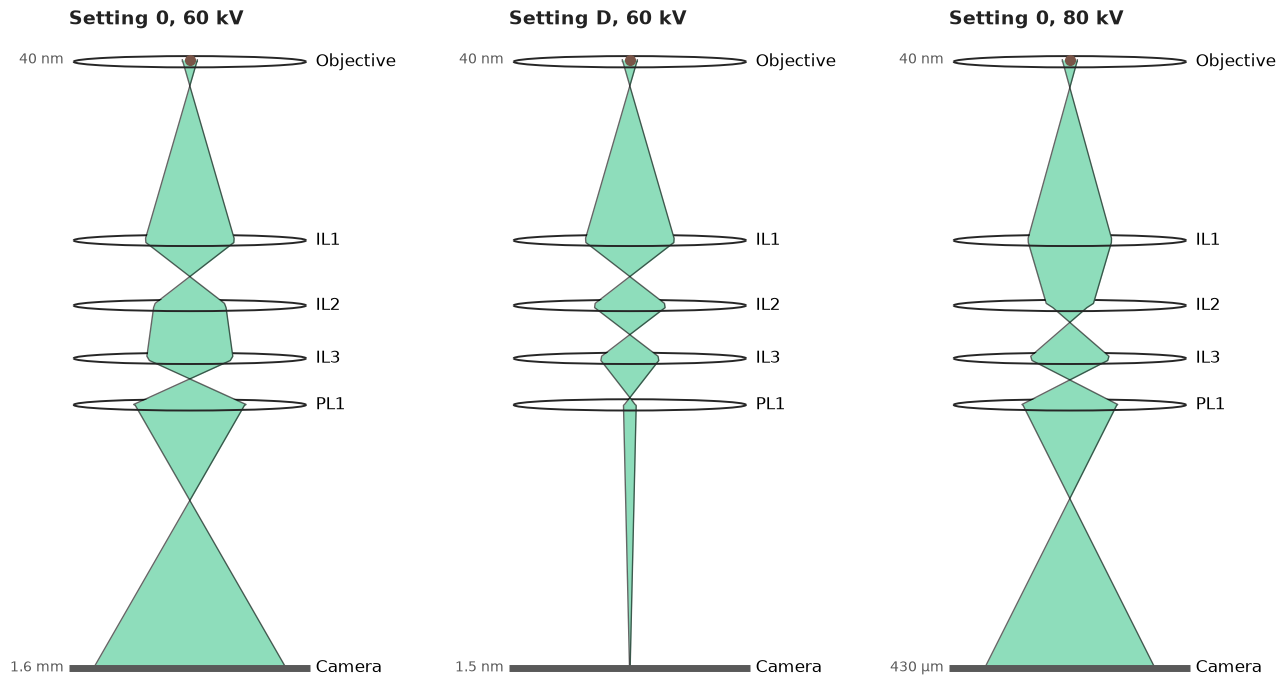

In [2]:
green = ("#222222", "#43C78E")
F.column_panels([("Setting 0, 60 kV", TRUTH, setup.sets[0], 60e3, *green),
                 ("Setting D, 60 kV", TRUTH, setup.sets[8], 60e3, *green),
                 ("Setting 0, 80 kV", TRUTH, setup.sets[0], 80e3, *green)], setup.v0, setup.camera);

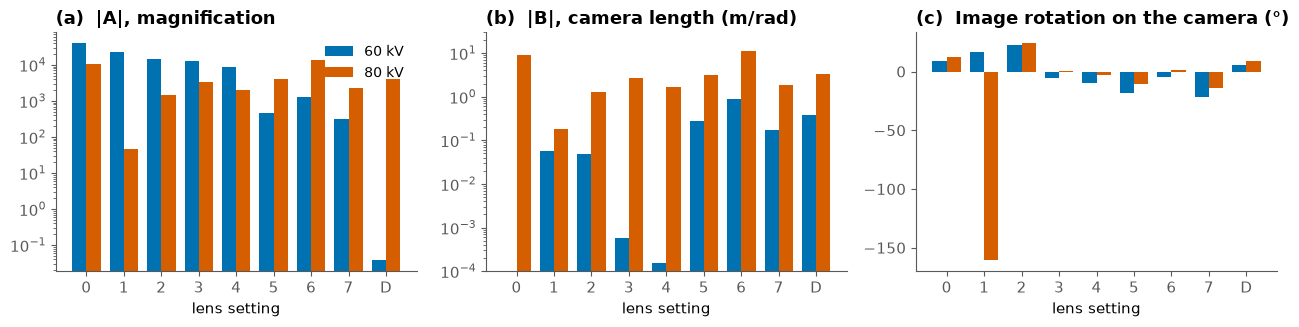

In [3]:
F.responses_figure(TRUTH, setup, scope.camera_rotation)

## 2. Pilot: the centroid floor

Ten repeats of one ± shift pair at setting 0. The scatter of the measured displacement gives the
floor used in every fit.

In [4]:
halves = np.array([(P.centroid(scope.frame(setup.sets[0], 60e3, shift=10e-9), setup.camera)
                    - P.centroid(scope.frame(setup.sets[0], 60e3, shift=-10e-9), setup.camera)) / 2 for _ in range(10)])
floor = np.sqrt((halves.real.var(ddof=1) + halves.imag.var(ddof=1)) / 2) * np.sqrt(2)
F.table(["", "value"], [["measured floor (px per frame and axis)", f"{floor:.4f}"], ["simulated", "0.0100"]])

|  | value |
|---|---|
| measured floor (px per frame and axis) | 0.0076 |
| simulated | 0.0100 |

## 3. Stage 1: lens setting + kick → beam position

At each lens setting:
1. a frame without a kick, to keep the beam on the camera;
2. a small test shift and tilt;
3. a ± shift and a ± tilt, each scaled to move the beam about 50 px, within the camera and the
   deflector range.

The measurement is half the difference of the two centroids, so the beam's starting position
cancels. Commands are in the console's nominal units; their true scale is unknown (here +7%
and −6%).

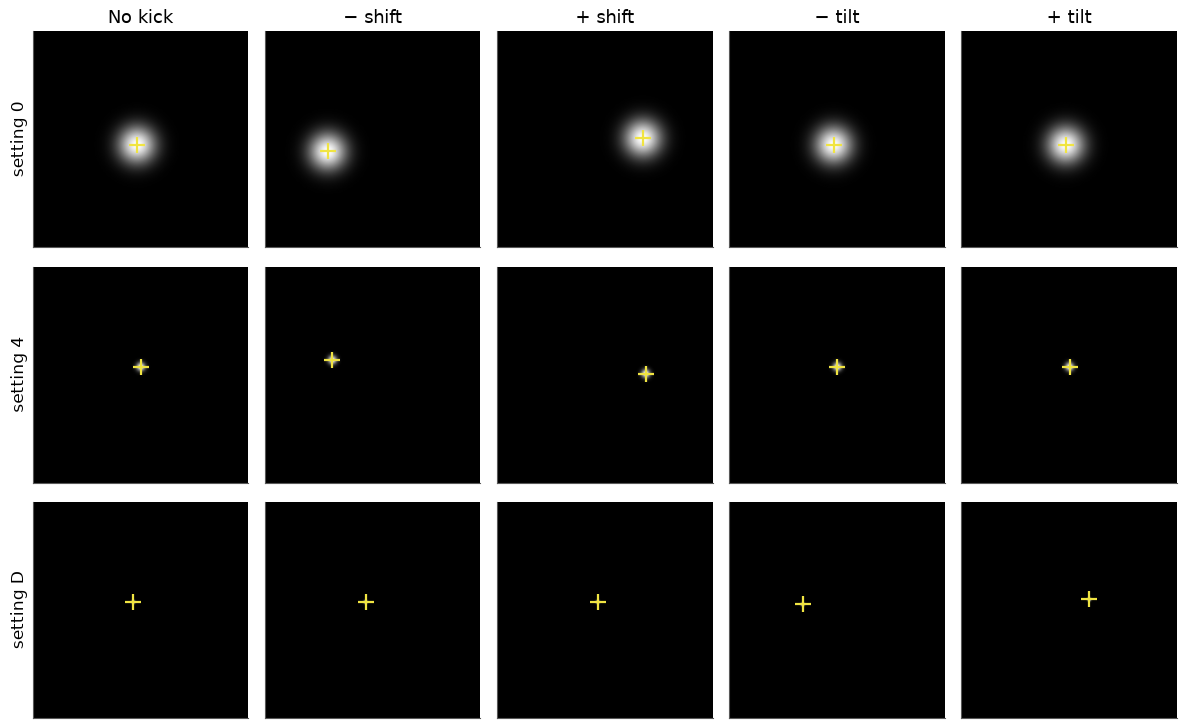

In [5]:
data1, frames = P.acquire(scope, setup, setup.sets, (60e3,), frames_for=(0, 4, 8))
F.frames_figure(frames, setup)

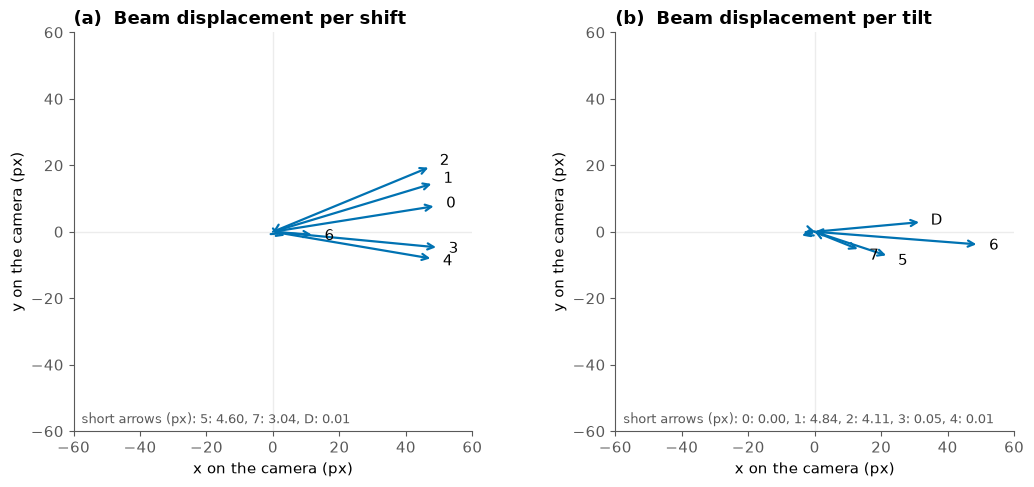

In [6]:
F.displacements_figure(data1, setup)

Each arrow is one complex measurement: how far and in which direction the beam moved. Short
arrows are real: there the deflector reached its limit before 50 px. Tilts at setting 0 are
short because the image is in focus ($B \approx 0$); shifts at setting D because $A = 0$.

**Fit 1** uses no specimen. The kick scales stay at 1, so the model works in kick units. With one
HT the camera distance and rotation are fixed by convention (gauges).

| fit 1 | value |
|---|---|
| χ²/dof (accepted at 99%) | 0.84 (True) |
| beam error, 50 px shift, median / 95% | 0.020 / 0.035 px |
| beam error, 50 px tilt, median / 95% | 0.017 / 0.043 px |

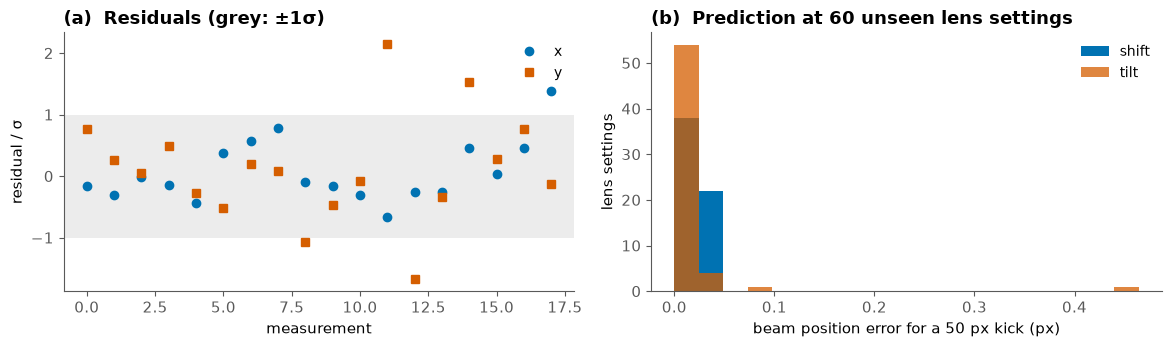

In [7]:
fit1 = P.fit(data1, setup, free=P.ONE_HT_FREE)
unseen = P.held_out_settings(setup)
es, et = P.beam_position_error_px(fit1, scope, setup, unseen)
F.table(["fit 1", "value"], [
    ["χ²/dof (accepted at 99%)", f"{fit1['chi2'] / fit1['dof']:.2f} ({fit1['accepted']})"],
    ["beam error, 50 px shift, median / 95%", f"{np.median(es):.3f} / {np.percentile(es, 95):.3f} px"],
    ["beam error, 50 px tilt, median / 95%", f"{np.median(et):.3f} / {np.percentile(et, 95):.3f} px"]])
F.stage1_fit_figure(fit1, data1, es, et)

Stage 1 alone is enough to drive the microscope: it predicts where a kick puts the beam at
unseen lens settings to a few hundredths of a pixel. It says nothing about lens positions; with
one HT many columns fit the same data.

## 4. Anchors: metres and radians

Two frames with the specimen in, both simulated with TemGym's Gaussian-beam (Collins) transform
through the hidden column:
- **Cross grating at setting 0.** The centres of the 3 × 3 squares are fitted with a lattice.
  $|A|$ = lattice period × pixel size / grating period (233 nm).
- **Gold at setting D.** The ring radii are $|B|\,\lambda/d$, with $\lambda$ = 4.87 pm at 60 kV and the
  Au(111) and Au(200) spacings.

| anchor | measured | truth | error |
|---|---|---|---|
| \|A\| at setting 0 | 39,993.2 | 40,000.0 | -0.017% |
| \|B\| at setting D (m/rad) | 0.37888 | 0.37884 | +0.010% |

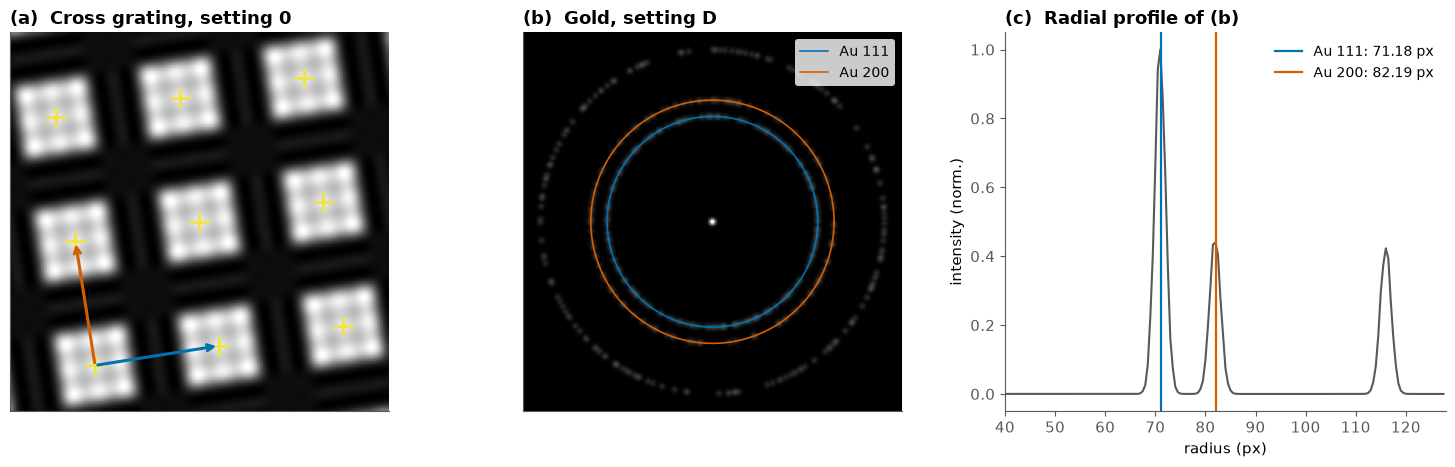

In [8]:
PERIOD = 0.70e-6 / 3
grating = scope.grating_image(setup.sets[0], PERIOD)
period_px, lattice, centres = P.grating_period_px(grating)
rings = scope.ring_pattern(setup.set_d)
radii, ring_info = P.ring_radii_px(rings, setup.camera)
magnification = period_px * setup.camera.pitch / PERIOD
b_abs = np.mean([radii[k] * setup.camera.pitch * P.AU_RINGS[k] / P.wavelength(setup.v0) for k in radii])
a_true, b_true = P.responses(TRUTH[:16], setup.sets[[0, 8]], 60e3, 60e3)
F.table(["anchor", "measured", "truth", "error"], [
    ["\\|A\\| at setting 0", f"{magnification:,.1f}", f"{abs(a_true[0]):,.1f}", f"{magnification / abs(a_true[0]) - 1:+.3%}"],
    ["\\|B\\| at setting D (m/rad)", f"{b_abs:.5f}", f"{abs(b_true[1]):.5f}", f"{b_abs / abs(b_true[1]) - 1:+.3%}"]])
F.anchors_figure(grating, centres, lattice, rings, radii, ring_info, setup.camera)

The measurements are good to 0.02% (grating) and 0.01% (rings). What they cannot see is how far
this patch of grating is from its certified period, since replica gratings vary from cell to
cell. The fit is therefore told 0.5% for the grating and 0.1% for the rings.

**Fit 2** adds the two anchors and frees the two kick scales.

In [9]:
anchors = P.make_anchors(a_dac=setup.sets[0], magnification=magnification, magnification_sigma=5e-3,
                         b_dac=setup.set_d, b_abs=b_abs, b_sigma=1e-3)
fit2 = P.fit(data1, setup, free=P.ONE_HT_FREE + [P.LOG_KS, P.LOG_KT], anchors=anchors)
k = np.exp(fit2["theta"][[P.LOG_KS, P.LOG_KT]])
sd = np.sqrt(np.diag(fit2["covariance"]))[[fit2["free"].index(P.LOG_KS), fit2["free"].index(P.LOG_KT)]]
ab = P.map_errors(fit2, scope, setup, unseen, absolute=True)
F.table(["fit 2", "fitted", "truth"], [
    ["χ²/dof (accepted)", f"{fit2['chi2'] / fit2['dof']:.2f} ({fit2['accepted']})", ""],
    ["shift scale", f"{k[0]:.4f} ± {k[0] * sd[0]:.4f}", f"{1 + scope.kick_errors[0]:.4f}"],
    ["tilt scale", f"{k[1]:.4f} ± {k[1] * sd[1]:.4f}", f"{1 + scope.kick_errors[1]:.4f}"],
    ["\\|A\\| error at unseen settings (median)", f"{np.median(np.abs(ab['magnification'])):.3%}", ""],
    ["\\|B\\| error at unseen settings (median)", f"{np.median(np.abs(ab['b'])):.3%}", ""]])

| fit 2 | fitted | truth |
|---|---|---|
| χ²/dof (accepted) | 0.84 (True) |  |
| shift scale | 1.0702 ± 0.0054 | 1.0700 |
| tilt scale | 0.9399 ± 0.0009 | 0.9400 |
| \|A\| error at unseen settings (median) | 0.016% |  |
| \|B\| error at unseen settings (median) | 0.011% |  |

## 5. Stage 2: lens and camera positions

**2a.** The HT goes to 80 kV and stage 1 is replayed with the same DAC values. Each lens is now
exactly p(60)/p(80) = 0.858 times as strong. That known change makes the positions measurable.
**Fit 3** uses both HTs.

The design step then uses fit 3 to choose 30 new lens settings: random DAC-feasible candidates
whose beam is predicted to stay on the camera at both HTs, added greedily to shrink the predicted
position errors.

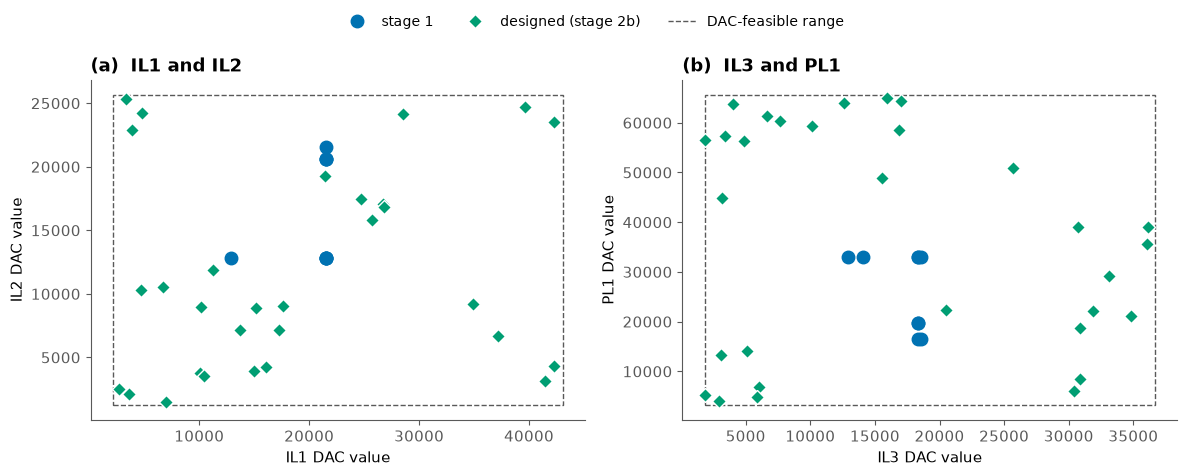

In [10]:
data2a, _ = P.acquire(scope, setup, setup.sets, (80e3,))
first = P.merge(data1, data2a)
fit3 = P.fit(first, setup, free=P.TWO_HT_FREE + [P.LOG_KS, P.LOG_KT], anchors=anchors)
designed = P.design_settings(fit3, setup, n_settings=30, seed=1)
F.design_figure(setup, designed)

**2b.** The 30 designed settings are measured at both HTs (240 frames), and **fit 4** uses
everything.

| position (mm) | truth | after 2a: error ± σ | after 2b: error ± σ |
|---|---|---|---|
| Objective | 2.30 | +0.001 ± 0.012 | -0.001 ± 0.012 |
| IL1 | 213.52 | +2.913 ± 2.432 | -0.020 ± 0.772 |
| IL2 | 290.48 | +5.368 ± 4.381 | -0.022 ± 0.904 |
| IL3 | 352.98 | +7.917 ± 6.435 | -0.022 ± 0.956 |
| PL1 | 407.98 | +10.498 ± 8.568 | -0.021 ± 0.964 |
| Detector | 718.75 | +16.545 ± 13.410 | +0.060 ± 0.723 |

fit 3 chi2/dof 1.24;  fit 4 chi2/dof 1.05 (accepted True)


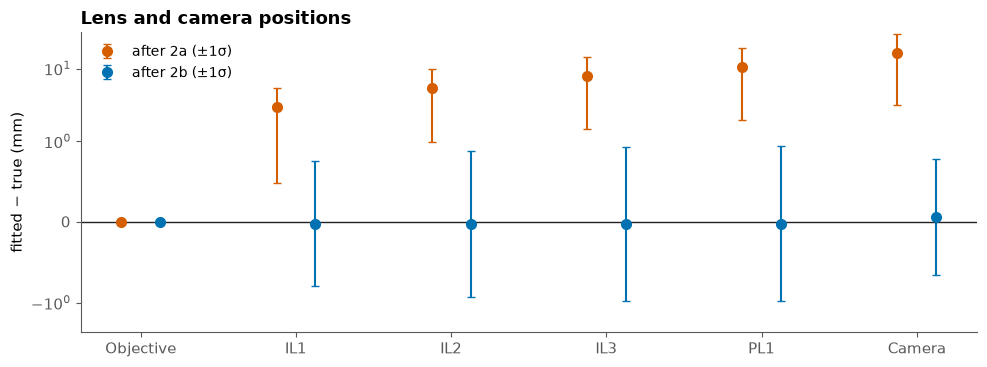

In [11]:
data2b, _ = P.acquire(scope, setup, designed, (60e3, 80e3))
fit4 = P.fit(P.merge(first, data2b), setup, free=P.TWO_HT_FREE + [P.LOG_KS, P.LOG_KT], anchors=anchors,
             start=fit3["theta"])
truth_mm = P.positions_mm(TRUTH)
fits = {"after 2a": P.position_errors(fit3), "after 2b": P.position_errors(fit4)}
F.table(["position (mm)", "truth", "after 2a: error ± σ", "after 2b: error ± σ"],
        [[name, f"{t:.2f}", *[f"{p[i] - t:+.3f} ± {s[i]:.3f}" for p, s in fits.values()]]
         for i, (name, t) in enumerate(zip(P.POSITION_NAMES, truth_mm))])
print(f"fit 3 chi2/dof {fit3['chi2'] / fit3['dof']:.2f};  fit 4 chi2/dof {fit4['chi2'] / fit4['dof']:.2f} "
      f"(accepted {fit4['accepted']})")
F.positions_figure(fits, truth_mm)

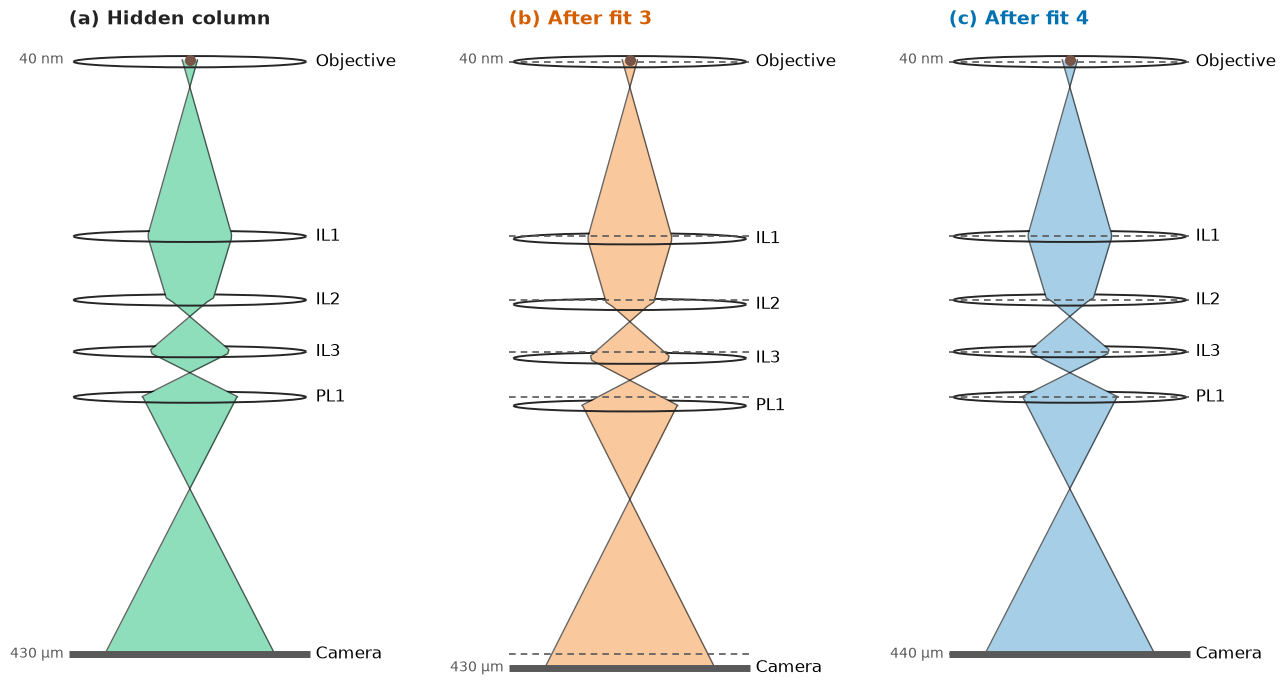

In [12]:
F.column_panels([("(a) Hidden column", TRUTH, setup.sets[0], 80e3, "#222222", "#43C78E"),
                 ("(b) After fit 3", fit3["theta"], setup.sets[0], 80e3, "#D55E00", "#F5A35C"),
                 ("(c) After fit 4", fit4["theta"], setup.sets[0], 80e3, "#0072B2", "#6BAED6")],
                setup.v0, setup.camera, truth=TRUTH);

Setting 0 at 80 kV, as in the paper figure. The dashed lines in (b) and (c) are the true lens and
camera planes. After fit 3 (stage 2a) the lenses and camera sit millimetres off. After fit 4
(stage 2b) they sit on the dashed lines, to about 1 mm.

## 6. Are the error bars honest?

On the microscope the fit's own error bars are all there is. The whole calibration is repeated
8 times. Each run draws fresh deflector scales, camera rotation, centroid floor and anchor errors
(0.5% grating, 0.1% rings). If the error bars are honest, error / σ scatters with rms about 1.

The anchors are drawn here, not measured from images, to save time. Every run uses the same
hidden column; robustness on other columns is a separate test.

| position | rms error (mm) | mean σ (mm) | rms z |
|---|---|---|---|
| Objective | 0.008 | 0.012 | 0.71 |
| IL1 | 0.562 | 0.772 | 0.73 |
| IL2 | 0.671 | 0.904 | 0.74 |
| IL3 | 0.726 | 0.956 | 0.76 |
| PL1 | 0.752 | 0.964 | 0.78 |
| Detector | 0.767 | 0.722 | 1.06 |

fits at the noise level: 8/8


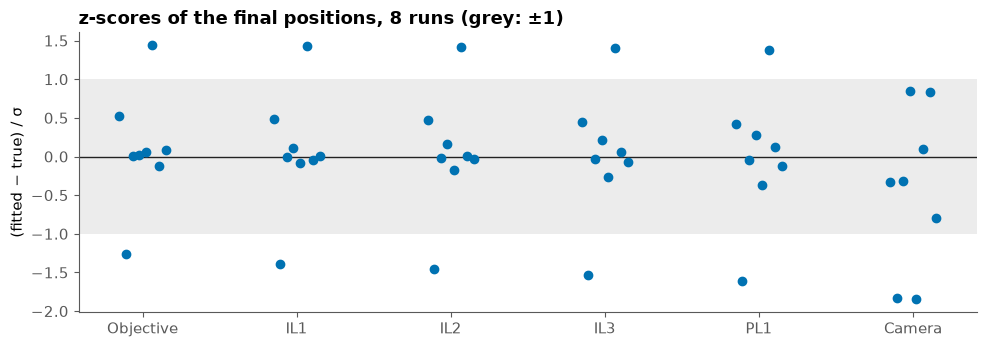

In [13]:
rng = np.random.default_rng(11)
z_scores, errors, accepted = [], [], []
for run in range(8):
    sim = P.SimulatedMicroscope(v0=60e3, kick_errors=tuple(rng.uniform(-0.1, 0.1, 2)),
                                camera_rotation=rng.uniform(-np.pi, np.pi), seed=100 + run)
    a_t, b_t = P.responses(sim.truth()[:16], setup.sets[[0, 8]], 60e3, 60e3)
    anc = P.make_anchors(a_dac=setup.sets[0], magnification=abs(a_t[0]) * (1 + rng.normal(0, 5e-3)), magnification_sigma=5e-3,
                         b_dac=setup.set_d, b_abs=abs(b_t[1]) * (1 + rng.normal(0, 1e-3)), b_sigma=1e-3)
    out = P.calibrate(sim, setup, anc, seed=run)
    pos, sig = P.position_errors(out["stage2b"])
    errors.append(pos - P.positions_mm(sim.truth())); z_scores.append(errors[-1] / sig)
    accepted.append(out["stage2b"]["accepted"])
errors, z_scores = np.array(errors), np.array(z_scores)
F.table(["position", "rms error (mm)", "mean σ (mm)", "rms z"],
        [[n, f"{np.sqrt((errors[:, i] ** 2).mean()):.3f}", f"{np.abs(errors[:, i] / z_scores[:, i]).mean():.3f}",
          f"{np.sqrt((z_scores[:, i] ** 2).mean()):.2f}"] for i, n in enumerate(P.POSITION_NAMES)])
print(f"fits at the noise level: {sum(accepted)}/{len(accepted)}")
F.zscore_figure(z_scores)

One run sits high at every position and another low at every position. The errors are
correlated because most of them come from one anchor error, which scales the whole column. So 8
runs are 8 samples, and an rms z of 0.7–1.1 is consistent with 1: the error bars are honest,
slightly conservative.

## 7. Summary

| level | frames | result here (0.01 px floor) |
|---|---|---|
| stage 1 | 36 | beam position for a 50 px kick to a few hundredths of a pixel, kick units |
| + anchors | 2 | kick scales to ~10⁻³; absolute maps limited by the 0.5% grating tolerance |
| stage 2a | +36 | lens positions to millimetres |
| stage 2b | +240 | lens positions to ~1 mm, the objective to ~0.01 mm |

**Assumed, not tested here:**
- the fit and the truth share the lens model;
- no hysteresis or DAC offsets;
- pure, linear deflectors;
- the 80 kV kick factor is known;
- one hidden column.

**Next:** the session script in PyJEM calls only, dry-run on the virtual NEOARM.